# Predicción Lineal

**22.46 Procesamiento Adaptativo de Señales Aleatorias — Trabajo Práctico 3**

# Grupo N° 5

| Integrante | Legajo |
|---|---|
| Albertine Gjøs | 69531 |
| Marek Myrebøe-Engels | 69476 |

In [99]:

from scipy import signal
import numpy as np
import soundfile as sf
from IPython.display import Audio, display
import matplotlib.pyplot as plt
from scipy.signal.windows import hann
import numpy as np


## 1. Grabación de Voz

In [100]:
# Should I normalize signals?
fs = 16000

a, fs_a = sf.read("data/a.wav", always_2d=True)
sh, fs_sh= sf.read("data/sh.wav", always_2d=True)

a = a.mean(axis=1)
a = signal.resample_poly(a, fs, fs_a)
a = a[0:1*fs] # 1 segundo
display(Audio(a, rate=fs))

sh = sh.mean(axis=1)
sh = signal.resample_poly(sh, fs, fs_sh)
sh = sh[0:fs] # 1 segundo
display(Audio(sh, rate=fs))

## 2. Predicción Lineal 

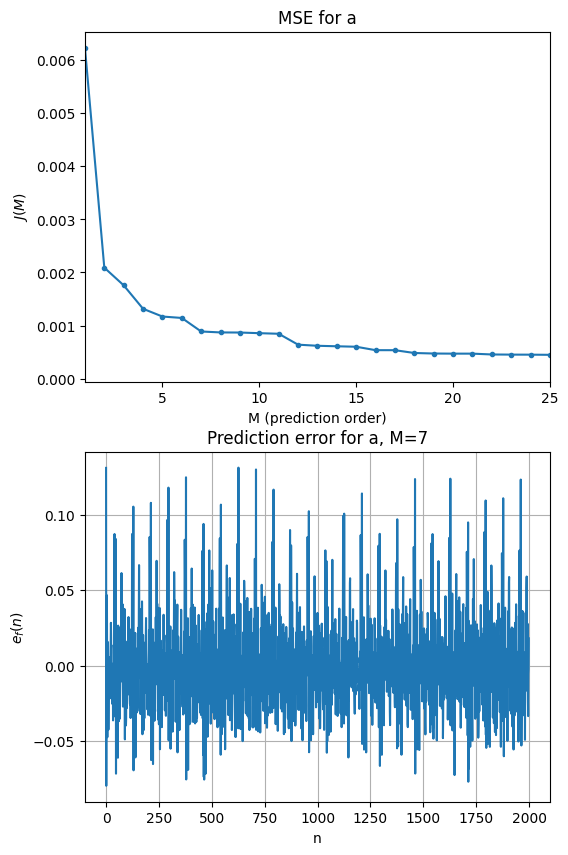

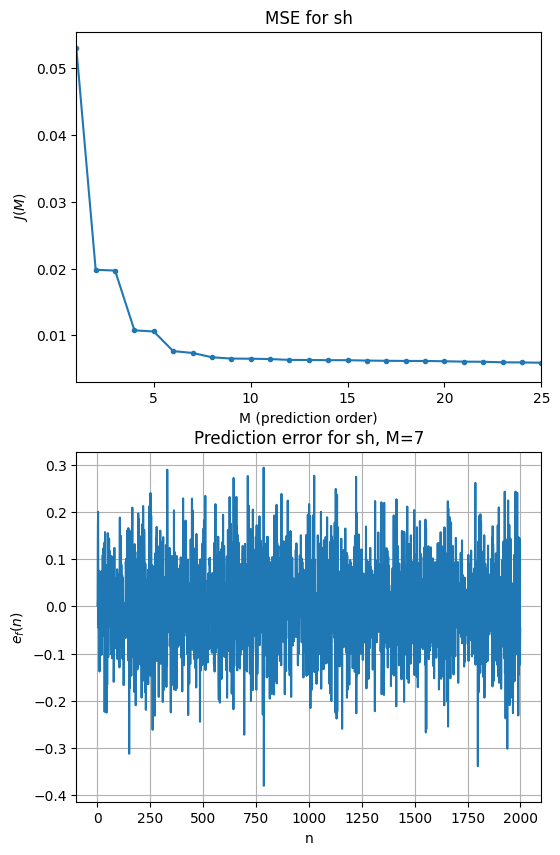

In [101]:

# Predicción forward
# Plot MSE J
# Dos codos para a y un para sh
# Recomendacion: Investigen error ef(n)
# ef(n) = x(n) + aH(n)x(n-1)
# Not investigated ef.......

def forward_prediction(x, M):
    N = len(x)

    # x[n-1], x[n-2], ..., x[n-M]
    X = np.array([
        x[n-M:n][::-1]
        for n in range(M, N)
    ])

    # x[n]
    d = x[M:N]

    R = X.conj().T @ X / len(d)
    r = X.conj().T @ d / len(d)

    # e_f(n) = x(n) + a^H x(n-1)
    ao = np.linalg.solve(R, -r)

    # Prediction error
    e = d + X @ ao

    # Minimum MSE
    # J = np.mean(np.abs(e)**2)
    sigma_x2 = np.vdot(d, d).real / len(d)
    Jo = sigma_x2 - np.vdot(-r, ao).real

    return ao.real, e, Jo


M_values = range(1, 71)

for x, name in zip([a, sh], ['a', 'sh']):

    J = []

    for M in M_values:
        ao, e, Jo = forward_prediction(x, M)
        J.append(Jo)
    fig, ax = plt.subplots(2, 1, figsize=(6, 10))
    ax[0].plot(M_values, J, "-o", markersize=3)
    ax[0].set_xlim(1, 25)
    ax[0].set_xlabel("M (prediction order)")
    ax[0].set_ylabel(r"$J(M)$")
    ax[0].set_title(f"MSE for {name}")

    M = 7
    ao, e, Jo = forward_prediction(x, M)

    ax[1].plot(e[:2000])
    ax[1].set_xlabel("n")
    ax[1].set_ylabel(r"$e_f(n)$")
    ax[1].set_title(f"Prediction error for {name}, M={M}")
    
    plt.grid()
    plt.show()
    

## 3. Dominio de Frecuencia

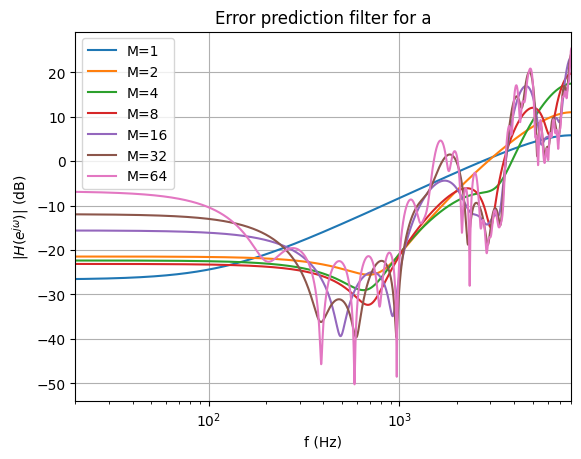

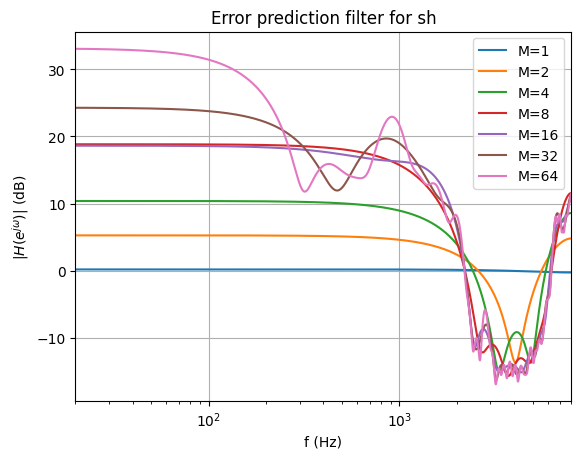

In [102]:
# Grabaciones en dominio de frecuencia
# representen la respuesta en frecuencia H(ejω) del filtro del error de predicción ā (no el filtro predictor a) 
# para M = 1, 2, 4, 8, 16, 32, 64. 
M_values = [1, 2, 4, 8, 16, 32, 64]

for x, name in zip([a, sh], ['a', 'sh']):

    plt.figure()

    for M in M_values:

        ao, e, J = forward_prediction(x, M)

        # Error prediction filter:
        # A_e(z) = 1 + a1 z^-1 + ... + aM z^-M
        A = np.concatenate(([1], ao))

        nfft = 2**16

        # Frequency response of error filter
        f, H = signal.freqz(A, worN=2**16, fs=fs)

        plt.semilogx(
            f,
            20*np.log10(np.maximum(np.abs(H), 1e-12)),
            label=f"M={M}"
        )

    plt.xlim(20, fs/2)
    plt.xlabel("f (Hz)")
    plt.ylabel(r"$|H(e^{j\omega})|$ (dB)")
    plt.title(f"Error prediction filter for {name}")
    plt.legend()
    plt.grid()
    plt.show()


Expliquen y justifiquen los resultados obtenidos, teniendo en cuenta J(M) y ef(n).

## 4. Resinteticar y Filtrar

Donde termina el primer codo, no el segundo

Period: 82 samples
f0: 195.1219512195122 Hz
Largest peak: 12926
Phase: 52
Original a


Resynthesized a


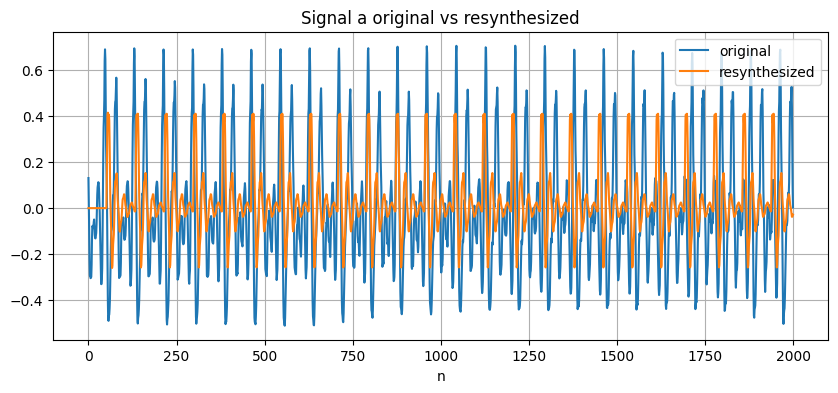

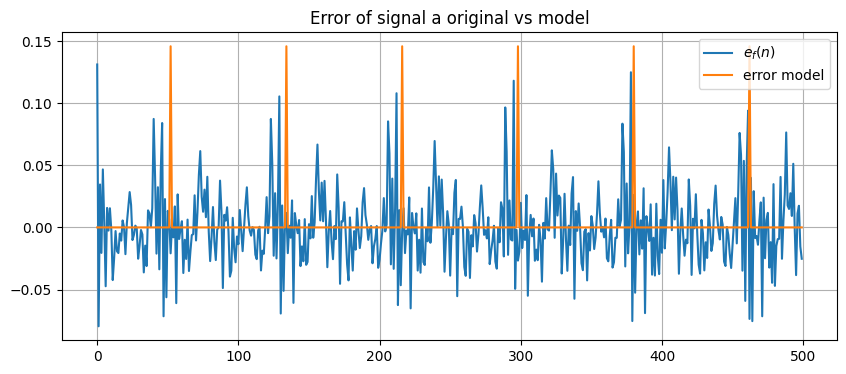

Original sh


Resynthesized sh


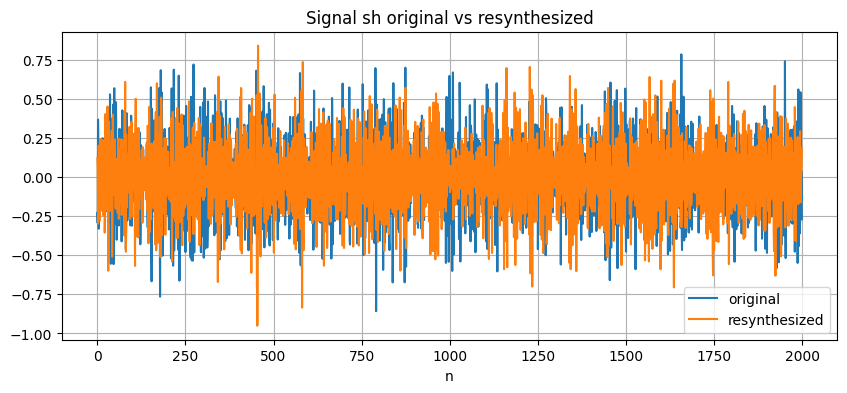

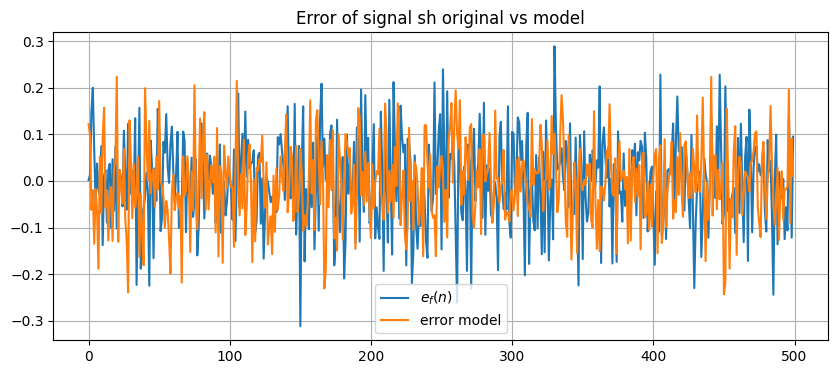

In [103]:
def find_period_and_phase(e):
    # Estimate pitch period
    # Remove DC
    e_centered = e - np.mean(e)
    # Autocorrelation
    corr = signal.correlate(e_centered, e_centered, mode="full")
    # Only non-negative lags
    corr = corr[len(corr)//2:]
    # Ignore lag 0
    period = np.argmax(corr[1:]) + 1
    f0 = fs / period
    print("Period:", period, "samples")
    print("f0:", f0, "Hz")
    
    # Find the phase that best matches the positive peaks of e
    peaks, _ = signal.find_peaks(e)
    peak = peaks[np.argmax(e[peaks])]
    phase = peak % period
    print("Largest peak:", peak)
    print("Phase:", phase)
    
    return period, phase


def error_model(e, name):
    e_model = []
    if name == "a":
        period, phase = find_period_and_phase(e)
        # Generate impulse train
        e_model = np.zeros(len(e))
        e_model[phase::period] = 1
        # Match peak amplitude
        e_model *= np.max(np.abs(e))
    elif name == "sh":
        # White-noise model
        e_model = np.random.randn(len(e))
        # Match RMS of prediction error
        e_model *= np.sqrt(np.mean(e**2) / np.mean(e_model**2)) 
    
    return e_model


M = 7

for x, name in zip([a, sh], ['a', 'sh']):
    ao, e, Jo = forward_prediction(x, M)
    A = np.concatenate(([1], ao))
    
    e_model = error_model(e, name)
    x_model = signal.lfilter([1], A, e_model)
    print(f"Original {name}")
    display(Audio(x, rate=fs))

    print(f"Resynthesized {name}")
    display(Audio(x_model, rate=fs))

    Nplot = min(2000, len(x_model))
    plt.figure(figsize=(10, 4))
    plt.plot(x[M:M+Nplot], label="original")
    plt.plot(x_model[:Nplot], label="resynthesized")
    plt.xlabel("n")
    plt.legend()
    plt.title(f"Signal {name} original vs resynthesized")
    plt.grid()
    plt.show()

    plt.figure(figsize=(10, 4))
    plt.plot(e[:500], label=r"$e_f(n)$")
    plt.plot(e_model[:500], label="error model")
    plt.legend()
    plt.title(f"Error of signal {name} original vs model")
    plt.grid()
    plt.show()

    

# Predicción Lineal

**22.46 Procesamiento Adaptativo de Señales Aleatorias — Trabajo Práctico 3**

# Grupo N° 5

| Integrante | Legajo |
|---|---|
| Albertine Gjøs | 69531 |
| Marek Myrebøe-Engels | 69476 |

In [104]:

from scipy import signal
import numpy as np
import soundfile as sf
from IPython.display import Audio, display
import matplotlib.pyplot as plt
from scipy.signal.windows import hann
import numpy as np


## 1. Grabación de Voz

In [105]:
# Should I normalize signals?
fs = 16000

a, fs_a = sf.read("data/a.wav", always_2d=True)
sh, fs_sh= sf.read("data/sh.wav", always_2d=True)

a = a.mean(axis=1)
a = signal.resample_poly(a, fs, fs_a)
a = a[0:1*fs] # 1 segundo
display(Audio(a, rate=fs))

sh = sh.mean(axis=1)
sh = signal.resample_poly(sh, fs, fs_sh)
sh = sh[0:fs] # 1 segundo
display(Audio(sh, rate=fs))

## 2. Predicción Lineal 

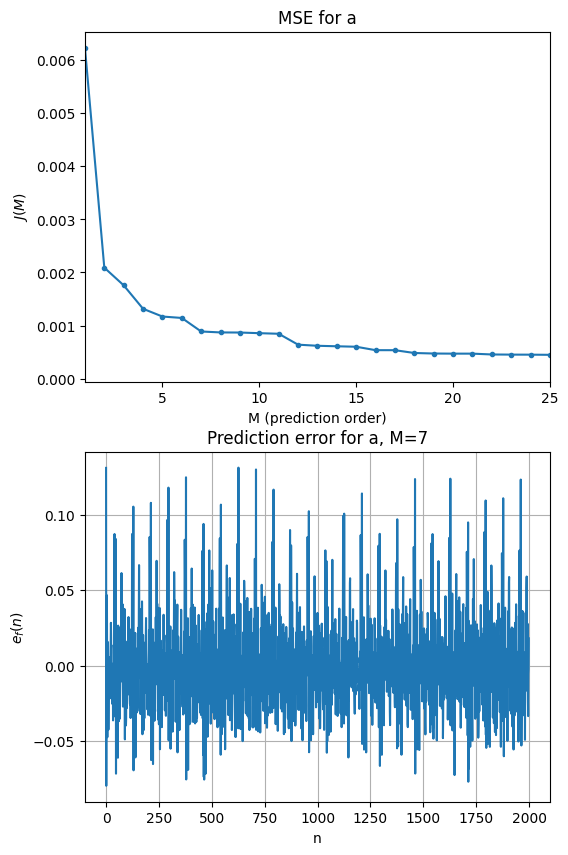

In [ ]:

# Predicción forward
# Plot MSE J
# Dos codos para a y un para sh
# Recomendacion: Investigen error ef(n)
# ef(n) = x(n) + aH(n)x(n-1)
# Not investigated ef.......

def forward_prediction(x, M):
    N = len(x)

    # x[n-1], x[n-2], ..., x[n-M]
    X = np.array([
        x[n-M:n][::-1]
        for n in range(M, N)
    ])

    # x[n]
    d = x[M:N]

    R = X.conj().T @ X / len(d)
    r = X.conj().T @ d / len(d)

    # e_f(n) = x(n) + a^H x(n-1)
    ao = np.linalg.solve(R, -r)

    # Prediction error
    e = d + X @ ao

    # Minimum MSE
    # J = np.mean(np.abs(e)**2)
    sigma_x2 = np.vdot(d, d).real / len(d)
    Jo = sigma_x2 - np.vdot(-r, ao).real

    return ao.real, e, Jo


M_values = range(1, 71)

for x, name in zip([a, sh], ['a', 'sh']):

    J = []

    for M in M_values:
        ao, e, Jo = forward_prediction(x, M)
        J.append(Jo)
    fig, ax = plt.subplots(2, 1, figsize=(6, 10))
    ax[0].plot(M_values, J, "-o", markersize=3)
    ax[0].set_xlim(1, 25)
    ax[0].set_xlabel("M (prediction order)")
    ax[0].set_ylabel(r"$J(M)$")
    ax[0].set_title(f"MSE for {name}")

    M = 7
    ao, e, Jo = forward_prediction(x, M)

    ax[1].plot(e[:2000])
    ax[1].set_xlabel("n")
    ax[1].set_ylabel(r"$e_f(n)$")
    ax[1].set_title(f"Prediction error for {name}, M={M}")
    
    plt.grid()
    plt.show()
    

## 3. Dominio de Frecuencia

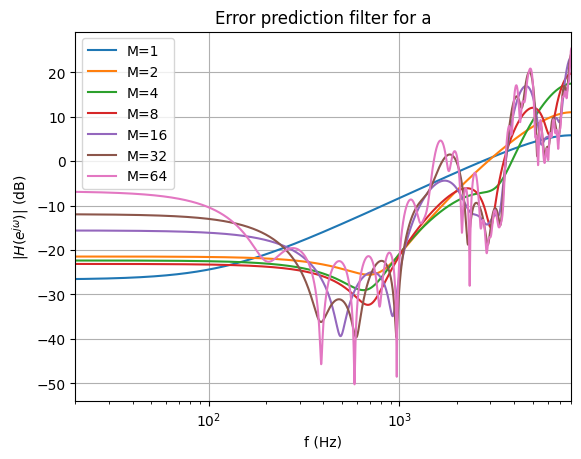

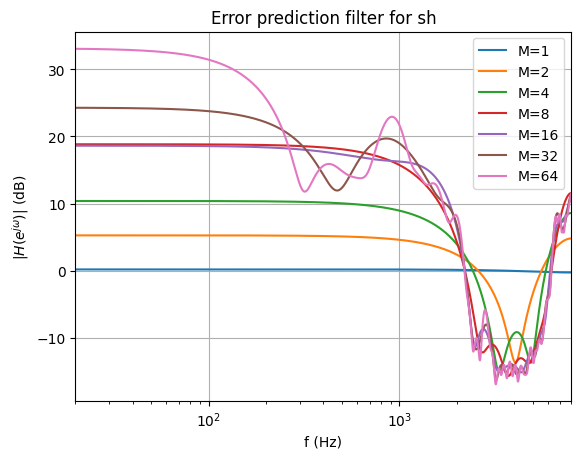

In [ ]:
# Grabaciones en dominio de frecuencia
# representen la respuesta en frecuencia H(ejω) del filtro del error de predicción ā (no el filtro predictor a) 
# para M = 1, 2, 4, 8, 16, 32, 64. 
M_values = [1, 2, 4, 8, 16, 32, 64]

for x, name in zip([a, sh], ['a', 'sh']):

    plt.figure()

    for M in M_values:

        ao, e, J = forward_prediction(x, M)

        # Error prediction filter:
        # A_e(z) = 1 + a1 z^-1 + ... + aM z^-M
        A = np.concatenate(([1], ao))

        nfft = 2**16

        # Frequency response of error filter
        f, H = signal.freqz(A, worN=2**16, fs=fs)

        plt.semilogx(
            f,
            20*np.log10(np.maximum(np.abs(H), 1e-12)),
            label=f"M={M}"
        )

    plt.xlim(20, fs/2)
    plt.xlabel("f (Hz)")
    plt.ylabel(r"$|H(e^{j\omega})|$ (dB)")
    plt.title(f"Error prediction filter for {name}")
    plt.legend()
    plt.grid()
    plt.show()


Expliquen y justifiquen los resultados obtenidos, teniendo en cuenta J(M) y ef(n).

## 4. Resinteticar y Filtrar

Donde termina el primer codo, no el segundo

Period: 82 samples
f0: 195.1219512195122 Hz
Largest peak: 12926
Phase: 52
Original a


Resynthesized a


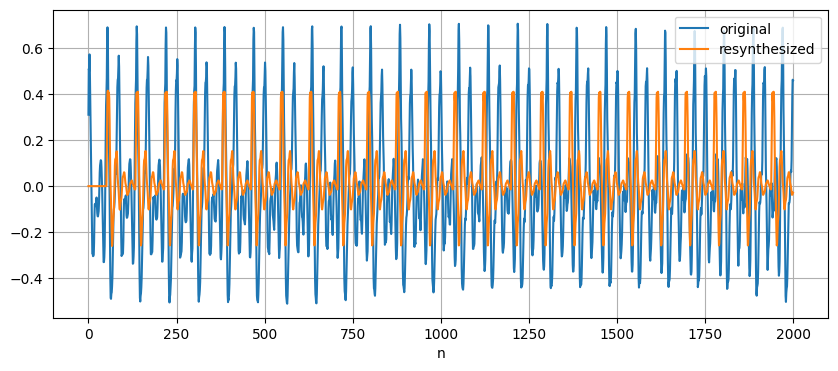

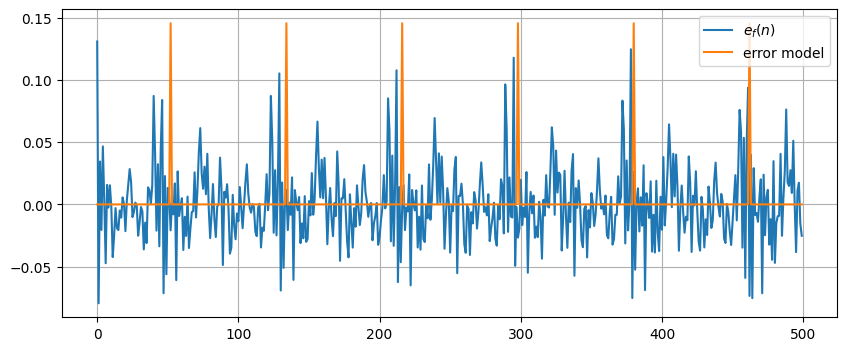

Original sh


Resynthesized sh


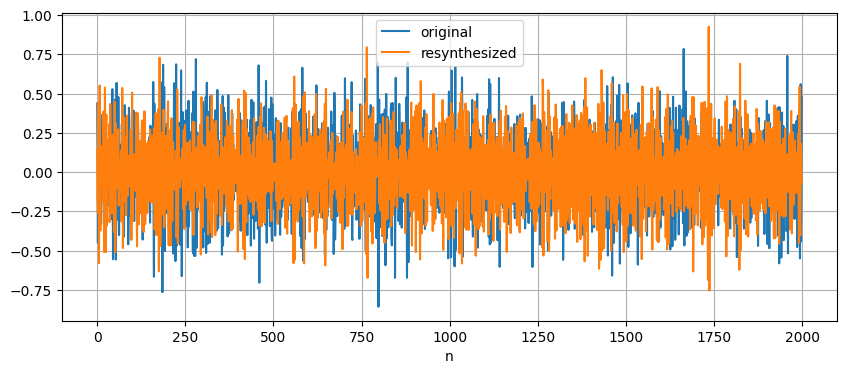

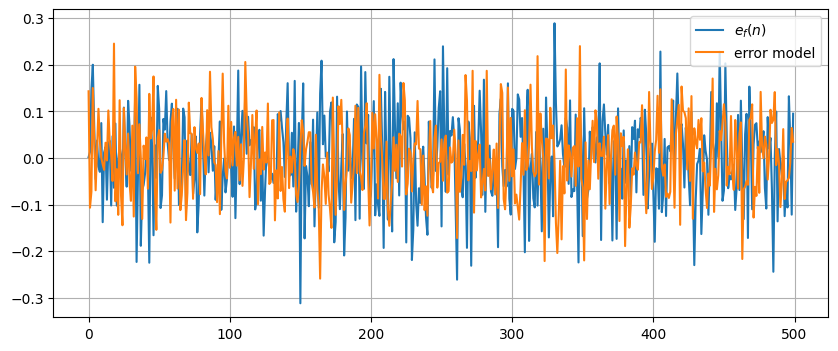

In [ ]:
def find_period_and_phase(e):
    # Estimate pitch period
    # Remove DC
    e_centered = e - np.mean(e)
    # Autocorrelation
    corr = signal.correlate(e_centered, e_centered, mode="full")
    # Only non-negative lags
    corr = corr[len(corr)//2:]
    # Ignore lag 0
    period = np.argmax(corr[1:]) + 1
    f0 = fs / period
    print("Period:", period, "samples")
    print("f0:", f0, "Hz")
    
    # Find the phase that best matches the positive peaks of e
    peaks, _ = signal.find_peaks(e)
    peak = peaks[np.argmax(e[peaks])]
    phase = peak % period
    print("Largest peak:", peak)
    print("Phase:", phase)
    
    return period, phase


def error_model(e, name):
    e_model = []
    if name == "a":
        period, phase = find_period_and_phase(e)
        # Generate impulse train
        e_model = np.zeros(len(e))
        e_model[phase::period] = 1
        # Match peak amplitude
        e_model *= np.max(np.abs(e))
    elif name == "sh":
        # White-noise model
        e_model = np.random.randn(len(e))
        # Match RMS of prediction error
        e_model *= np.sqrt(np.mean(e**2) / np.mean(e_model**2)) 
    
    return e_model


M = 7

for x, name in zip([a, sh], ['a', 'sh']):
    ao, e, Jo = forward_prediction(x, M)
    A = np.concatenate(([1], ao))
    
    e_model = error_model(e, name)
    x_model = signal.lfilter([1], A, e_model)
    print(f"Original {name}")
    display(Audio(x, rate=fs))

    print(f"Resynthesized {name}")
    display(Audio(x_model, rate=fs))

    plt.figure(figsize=(10, 4))
    plt.plot(x[:2000], label="original")
    plt.plot(x_model[:2000], label="resynthesized")
    plt.xlabel("n")
    plt.legend()
    plt.grid()
    plt.show()

    plt.figure(figsize=(10, 4))
    plt.plot(e[:500], label=r"$e_f(n)$")
    plt.plot(e_model[:500], label="error model")
    plt.legend()
    plt.grid()
    plt.show()

    

Escuchen el resultado y compárenlo con la grabación original. Expliquen las diferencias. Justifiquen. 

## 5. Grabación Larga

In [ ]:
fs = 16000

voice, fs_voice = sf.read("data/voice.wav", always_2d=True)
voice = voice.mean(axis=1)
voice = signal.resample_poly(voice, fs, fs_voice)
voice = voice[fs:6*fs] # 5 segundo
display(Audio(voice, rate=fs))


L = int(0.05 * fs)     # 50 ms
D = L // 2             # 50% overlap
M = 12

w = hann(L)

output = np.zeros(len(voice))
starts = range(0, len(voice) - L + 1, D)

period = int(fs / 160) # 100 samples

for s in starts:
    # Extra block
    seg = voice[s:s+L]
    # Hann window
    seg_w = seg * w
    # Forward prediction
    ao, e, Jo = forward_prediction(seg_w, M=12)
    # Error prediction filter
    A = np.concatenate(([1], ao))
    # Global 160 Hz impulse train
    global_indices = np.arange(s, s+L)
    
    e_model = np.zeros(L)
    e_model[global_indices % period == 0] = 1
    # Match RMS of this block
    e_model *= np.sqrt(np.mean(e**2) / np.mean(e_model**2))
    # Inverse error prediction filter
    synthesized = signal.lfilter([1], A, e_model)
    # Window synthesized block
    synthesized_w = synthesized * w
    # Overlap-add
    output[s:s+L] += synthesized_w

display(Audio(output, rate=fs))



Escuchen la señal sumada y comparen con la grabación. ¿Qué ocurre? Justifiquen

Escuchen el resultado y compárenlo con la grabación original. Expliquen las diferencias. Justifiquen. 

## 5. Grabación Larga

In [ ]:
fs = 16000

voice, fs_voice = sf.read("data/voice.wav", always_2d=True)
voice = voice.mean(axis=1)
voice = signal.resample_poly(voice, fs, fs_voice)
voice = voice[fs:6*fs] # 5 segundo
display(Audio(voice, rate=fs))


L = int(0.05 * fs)     # 50 ms
D = L // 2             # 50% overlap
M = 12

w = hann(L)

output = np.zeros(len(voice))
starts = range(0, len(voice) - L + 1, D)

period = int(fs / 160) # 100 samples

for s in starts:
    # Extra block
    seg = voice[s:s+L]
    # Hann window
    seg_w = seg * w
    # Forward prediction
    ao, e, Jo = forward_prediction(seg_w, M=12)
    # Error prediction filter
    A = np.concatenate(([1], ao))
    # Global 160 Hz impulse train
    global_indices = np.arange(s, s+L)
    
    e_model = np.zeros(L)
    e_model[global_indices % period == 0] = 1
    # Match RMS of this block
    e_model *= np.sqrt(np.mean(e**2) / np.mean(e_model**2))
    # Inverse error prediction filter
    synthesized = signal.lfilter([1], A, e_model)
    # Window synthesized block
    synthesized_w = synthesized * w
    # Overlap-add
    output[s:s+L] += synthesized_w

display(Audio(output, rate=fs))



Escuchen la señal sumada y comparen con la grabación. ¿Qué ocurre? Justifiquen